# EDA de COVID-19 en Estados Unidos — nivel medio

**Proyecto de Fabiana · guía de estudio en español**

EDA significa **análisis exploratorio de datos**. Antes de predecir o explicar un fenómeno, debemos descubrir qué contiene la tabla, qué problemas presenta y qué permiten afirmar los datos.

Imagina el encargo del cliente: «Organizad estos datos y contadme qué ocurrió». La entrega tiene dos formas de comunicación: este notebook documenta el razonamiento técnico; el informe de dos páginas presenta las conclusiones a quien no programa.

**Cómo estudiar:** lee el texto, ejecuta únicamente la siguiente celda con **Shift + Enter**, observa la salida y lee su interpretación. Las celdas comparten variables: ejecútalas en orden. Al terminar, reinicia el kernel y ejecuta todo para comprobar la reproducibilidad.

**Recorrido:** 1. comprender el encargo; 2. preparar las herramientas; 3. cargar; 4. inspeccionar; 5. limpiar; 6. crear variables; 7. estudiar una variable; 8. investigar valores atípicos; 9. agrupar; 10. relacionar variables; 11. estudiar el tiempo; 12. analizar correlaciones; 13. responder; 14. generar el informe.

Los datos son históricos; la recopilación terminó el **7 de marzo de 2021**. No describen la situación actual.


## 1. Leer el enunciado y convertir el encargo en preguntas

El [enunciado original](../docs/enunciado.md) establece una semana y permite elegir el dataset. Elegimos la fuente sugerida, el COVID Tracking Project, y el **nivel medio**, que incluye todos los requisitos esenciales.

| El enunciado pide | Qué haremos |
|---|---|
| Comprender la estructura | shape, info, head y describe |
| Limpiar y justificar | Duplicados, tipos, nulos, selección y renombrado |
| Tres variables por separado | Casos acumulados, estado y fallecimientos acumulados |
| Tres relaciones | Estado × casos, casos × fallecimientos, fecha × incrementos |
| Al menos cinco gráficos | Histogramas, barras, boxplot, dispersión, líneas y mapas de calor |
| Tres preguntas respondidas | Las preguntas siguientes, con cifras calculadas |
| Valores atípicos | Regla del rango intercuartílico y decisión documentada |
| groupby, agg y pivot_table | Resúmenes por estado, día y mes |
| Al menos tres variables nuevas | Año, mes, día de la semana e indicadores de corrección |
| Correlación y tiempo | Mapa de calor y series diarias |
| Informe de 1 a 2 páginas | PDF con conclusiones, gráficos y limitaciones |

### Preguntas formuladas antes del análisis

1. **¿Cómo evolucionaron los registros diarios de casos y fallecimientos?** ¿En qué fechas se observaron los mayores incrementos netos registrados?
2. **¿Qué estados o territorios concentraron más casos acumulados en la misma fecha final?**
3. **¿Existe asociación entre los casos y los fallecimientos acumulados por jurisdicción en esa fecha?**
4. **¿Qué problemas limitan la interpretación, especialmente de las hospitalizaciones?**

**Hipótesis que investigar, no conclusiones:** la serie puede presentar olas; los totales pueden concentrarse en pocas jurisdicciones; casos y fallecimientos pueden variar juntos. Lo comprobaremos, sin darlo por hecho.

Este dataset no contiene la población. Por tanto, «más casos acumulados» significa **mayor volumen registrado**, y no necesariamente mayor riesgo por habitante.


### 1.1. Comprender qué representa una fila

Cada fila representa **un estado o territorio en una fecha de recogida de datos**. La clave natural es **estado + fecha**. Las 56 jurisdicciones incluyen estados, el Distrito de Columbia y territorios; no son 56 estados.

| Concepto | Ejemplo sencillo | Consecuencia |
|---|---|---|
| Acumulado | 100 casos ayer, 110 hoy | No sumar 100 + 110 para afirmar que hubo 210 casos |
| Incremento diario | 110 − 100 = 10 | Puede sumarse entre fechas, respetando las revisiones y la cobertura |
| Medida del momento | 20 personas hospitalizadas hoy | Sumar días no produce el número de personas únicas hospitalizadas |
| Nulo | El estado no informó de un valor | No equivale a cero |
| Corrección negativa | El acumulado se revisó de 110 a 108 | El incremento de −2 es una revisión; no son «casos negativos» |

La fecha corresponde a la **recogida/notificación**, no necesariamente a la infección o al fallecimiento. Un pico puede reflejar notificaciones atrasadas.

Fuentes: [descarga oficial](https://covidtracking.com/data/download/) y [definiciones oficiales](https://covidtracking.com/about-data/data-definitions/).


## 2. Preparar las herramientas

Para usar **Google Colab dentro de VS Code**, instala la extensión oficial **Colab**, de Google, y **Jupyter**, de Microsoft. Abre **Select Kernel → Colab → Auto Connect** e inicia sesión con tu cuenta de Google. Este EDA puede ejecutarse con CPU.

Después de conectar, haz clic derecho en la carpeta **scripts** del explorador y elige **Upload to Colab**. En **Colab → Contents**, comprueba que existen `/content/scripts/descargar_datos.py` y `/content/scripts/generar_informe.py`. El notebook utiliza estos dos archivos; el CSV se descarga automáticamente. Repite el envío al conectar con un servidor nuevo.

En Colab, las bibliotecas y los archivos generados están en el servidor remoto. Si falta alguna biblioteca, ejecuta `%pip install pandas numpy matplotlib seaborn requests` en una celda temporal, reinicia el kernel y vuelve a ejecutar. Guarda el notebook con **Cmd + S** para conservar sus salidas; para conservar también el PDF, las tablas y los datos, sigue las instrucciones de Google Drive del [README](../README.md#google-colab-dentro-de-vs-code).

**Alternativa local:** un entorno virtual separa las bibliotecas de este proyecto. Ejecuta **bash scripts/preparar_entorno.sh** en el terminal y selecciona el Python de **.venv** en **Select Kernel**.

En la siguiente celda, **import** carga herramientas y **as** crea un alias. pandas (pd) trabaja con tablas; numpy (np), con cálculos; matplotlib (plt) y seaborn (sns), con gráficos. Path representa rutas de archivos.


In [1]:
from pathlib import Path
import os
import sys

# Busca el proyecto local o los scripts enviados al servidor de Colab.
candidatos = [
    Path.cwd(), *Path.cwd().parents,
    Path("/content"), Path("/content/ai_project_EDA"),
]
ROOT = next(
    (p for p in candidatos
     if (p / "scripts/descargar_datos.py").is_file()
     and (p / "scripts/generar_informe.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "No se encuentra la carpeta scripts. En Colab desde VS Code, haz clic "
        "derecho en la carpeta scripts y elige Upload to Colab. "
        "Comprueba los dos archivos .py en /content/scripts. "
        "Con Python local, abre el notebook dentro de la carpeta del proyecto."
    )
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path.insert(0, str(ROOT / "scripts"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from descargar_datos import descargar_datos
from generar_informe import numero

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: numero(x, 2))
print("Carpeta del proyecto:", ROOT)
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__)


Carpeta del proyecto: /Volumes/SSD-FABI/workspace/factoria/IA SCHOOL/ai_project_EDA
Python: 3.14.6 | pandas: 3.1.0


### 2.1. Separar entrada y salida

**raw** conserva el archivo recibido; **processed**, la tabla preparada. Los resultados se guardan en **reports**. Esta organización permite volver a la fuente y explicar cada transformación.

La pequeña función siguiente solo guarda figuras. El argumento fig es el gráfico creado; nombre es el nombre del archivo PNG. Los datos y los cálculos siguen visibles en las siguientes celdas.


In [2]:
PROCESSED = ROOT / "data/processed"
FIGURES = ROOT / "reports/figures"
TABLES = ROOT / "reports/tables"
for carpeta in [PROCESSED, FIGURES, TABLES]:
    carpeta.mkdir(parents=True, exist_ok=True)

def guardar_figura(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIGURES / nombre, dpi=160, bbox_inches="tight")
    plt.show()

## 3. Cargar los datos oficiales

**CSV** es un archivo de texto que organiza filas y columnas. **DataFrame** es la tabla en memoria con la que trabaja pandas.

La función descargar_datos utiliza el CSV local si existe; solo accede a Internet en la primera ejecución. Comprueba la respuesta del servidor y registra la dirección, la fecha de descarga y el hash en data/raw/covid_us.metadata.json.

**df_bruto** conserva la entrada. Más adelante crearemos otra tabla para la limpieza. Así evitamos confundir los datos de la fuente con las transformaciones.


In [3]:
archivo = descargar_datos()
df_bruto = pd.read_csv(archivo)
print("Archivo cargado:", archivo.name)

Utilizando el archivo local: /Volumes/SSD-FABI/workspace/factoria/IA SCHOOL/ai_project_EDA/data/raw/covid_us.csv
Archivo cargado: covid_us.csv


## 4. Investigar antes de modificar

### 4.1. Dimensiones: shape

**shape** devuelve una pareja: primero el número de filas y después el de columnas. Cada columna es una variable; cada fila, una observación. No hacen falta paréntesis porque shape es una propiedad, no una función.


In [4]:
filas, columnas = df_bruto.shape
print(f"Filas: {filas:,} | Columnas: {columnas}")
print("Jurisdicciones:", df_bruto["state"].nunique())

Filas: 20,780 | Columnas: 56
Jurisdicciones: 56


### 4.2. Primeras filas: head

**head(5)** muestra cinco filas. Ayuda a reconocer nombres, formatos y ejemplos, pero no representa necesariamente toda la distribución. La fuente puede estar ordenada desde la fecha más reciente hasta la más antigua.


In [5]:
display(df_bruto.head(5))

,date,state,positive,probableCases,negative,pending,totalTestResultsSource,totalTestResults,hospitalizedCurrently,hospitalizedCumulative,...,dataQualityGrade,deathIncrease,hospitalizedIncrease,hash,commercialScore,negativeRegularScore,negativeScore,positiveScore,score,grade
0,20210307,AK,"56.886,00",NaN,NaN,NaN,totalTestsViral,"1.731.628,00","33,00","1.293,00",...,NaN,0,0,dc4bccd4bb885349d7e94d6fed058e285d4be164,0,0,0,0,0,NaN
1,20210307,AL,"499.819,00","107.742,00","1.931.711,00",NaN,totalTestsPeopleViral,"2.323.788,00","494,00","45.976,00",...,NaN,-1,0,997207b430824ea40b8eb8506c19a93e07bc972e,0,0,0,0,0,NaN
2,20210307,AR,"324.818,00","69.092,00","2.480.716,00",NaN,totalTestsViral,"2.736.442,00","335,00","14.926,00",...,NaN,22,11,50921aeefba3e30d31623aa495b47fb2ecc72fae,0,0,0,0,0,NaN
3,20210307,AS,"0,00",NaN,"2.140,00",NaN,totalTestsViral,"2.140,00",NaN,NaN,...,NaN,0,0,f77912d0b80d579fbb6202fa1a90554fc4dc1443,0,0,0,0,0,NaN
4,20210307,AZ,"826.454,00","56.519,00","3.073.010,00",NaN,totalTestsViral,"7.908.105,00","963,00","57.907,00",...,NaN,5,44,0437a7a96f4471666f775e63e86923eb5cbd8cdf,0,0,0,0,0,NaN


### 4.3. Tipos y valores presentes: info

**info()** muestra los tipos y las cantidades de valores no nulos. int/float representan números; str/object, texto. Una columna numérica puede aparecer como float porque contiene nulos.

Observa date: un número como 20210307 parece numérico, pero significa 7 de marzo de 2021. Calcular la media de esos números no es un análisis de fechas.


In [6]:
df_bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 20780 entries, 0 to 20779
Data columns (total 56 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   date                         20780 non-null  int64  
 1   state                        20780 non-null  str    
 2   positive                     20592 non-null  float64
 3   probableCases                9271 non-null   float64
 4   negative                     13290 non-null  float64
 5   pending                      2138 non-null   float64
 6   totalTestResultsSource       20780 non-null  str    
 7   totalTestResults             20614 non-null  float64
 8   hospitalizedCurrently        17339 non-null  float64
 9   hospitalizedCumulative       12382 non-null  float64
 10  inIcuCurrently               11636 non-null  float64
 11  inIcuCumulative              3789 non-null   float64
 12  onVentilatorCurrently        9126 non-null   float64
 13  onVentilatorCumulative     

### 4.4. Resumen numérico: describe

**count** cuenta valores conocidos; **mean** es la media; **std**, la desviación típica; **min/max**, los extremos. Los percentiles 25%, 50% y 75% dividen los datos ordenados; el 50% es la mediana.

En esta inspección mezclamos estados y fechas. El resumen sirve para detectar órdenes de magnitud y posibles problemas. Para comparar estados utilizaremos más adelante una misma fecha.


In [7]:
display(df_bruto.describe())

,date,positive,probableCases,negative,pending,totalTestResults,hospitalizedCurrently,hospitalizedCumulative,inIcuCurrently,inIcuCumulative,...,posNeg,dataQualityGrade,deathIncrease,hospitalizedIncrease,commercialScore,negativeRegularScore,negativeScore,positiveScore,score,grade
count,"20.780,00","20.592,00","9.271,00","13.290,00","2.138,00","20.614,00","17.339,00","12.382,00","11.636,00","3.789,00",...,"20.780,00","0,00","20.780,00","20.780,00","20.780,00","20.780,00","20.780,00","20.780,00","20.780,00","0,00"
mean,"20.202.440,02","165.155,97","21.729,12","848.224,62","1.659,86","2.186.935,75","1.190,58","9.262,76","359,62","1.934,19",...,"706.150,00",NaN,"24,79","37,36","0,00","0,00","0,00","0,00","0,00",NaN
std,"3.608,73","326.785,24","45.471,46","1.344.501,36","4.671,03","4.436.508,15","2.060,04","12.620,54","594,83","1.953,33",...,"1.299.996,54",NaN,"60,16","208,24","0,00","0,00","0,00","0,00","0,00",NaN
min,"20.200.113,00","0,00","0,00","0,00","0,00","0,00","0,00","1,00","0,00","6,00",...,"0,00",NaN,"-201,00","-12.257,00","0,00","0,00","0,00","0,00","0,00",NaN
25%,"20.200.602,00","5.753,75","773,50","53.941,25","43,00","104.049,75","166,50","985,25","60,00","501,00",...,"25.658,75",NaN,"0,00","0,00","0,00","0,00","0,00","0,00","0,00",NaN
50%,"20.200.903,00","46.064,50","4.491,00","305.972,00","212,50","655.267,00","531,00","4.472,00","172,00","1.295,00",...,"193.581,00",NaN,"6,00","0,00","0,00","0,00","0,00","0,00","0,00",NaN
75%,"20.201.205,00","177.958,00","19.553,00","1.056.611,25","1.295,75","2.264.766,50","1.279,00","12.248,50","380,00","2.451,00",...,"773.740,75",NaN,"24,00","36,00","0,00","0,00","0,00","0,00","0,00",NaN
max,"20.210.307,00","3.501.394,00","365.961,00","10.186.941,00","64.400,00","49.646.014,00","22.851,00","82.237,00","5.225,00","9.263,00",...,"11.248.247,00",NaN,"2.559,00","16.373,00","0,00","0,00","0,00","0,00","0,00",NaN


## 5. Limpiar sin borrar la historia de los datos

### 5.1. Comprobar duplicados

Hay dos comprobaciones distintas: filas completamente iguales y repetición de estado + fecha. Una clave repetida con valores diferentes es un **conflicto** que requiere investigación.

La siguiente regla elimina únicamente copias exactas, si existen. Si dos filas difieren para la misma clave, detiene el proceso en lugar de elegir una silenciosamente.


In [8]:
duplicados_exactos = int(df_bruto.duplicated().sum())
duplicados_clave = int(df_bruto.duplicated(["state", "date"]).sum())
print("Copias exactas:", duplicados_exactos)
print("Repeticiones de estado + fecha:", duplicados_clave)

base = df_bruto.drop_duplicates().copy()
if base.duplicated(["state", "date"]).any():
    raise ValueError("Hay registros contradictorios para estado + fecha; investigar antes de continuar.")

Copias exactas: 0
Repeticiones de estado + fecha: 0


### 5.2. Cuantificar valores ausentes

**isna()** marca cada celda ausente con True. **sum()** cuenta esas marcas por columna. La media de las marcas multiplicada por 100 proporciona el porcentaje de ausencia.

Examinaremos todas las columnas, no solo las primeras filas. Un umbral del 80% sirve como advertencia de escasa cobertura, no como regla automática para eliminar información.


In [9]:
calidad_original = pd.DataFrame({
    "nulos": base.isna().sum(),
    "porcentaje_nulos": base.isna().mean().mul(100),
    "tipo_original": base.dtypes.astype(str),
}).sort_values("porcentaje_nulos", ascending=False)

display(calidad_original)
print("Columnas con más del 80% de nulos:", int(calidad_original["porcentaje_nulos"].gt(80).sum()))
calidad_original.to_csv(TABLES / "calidad_columnas_originales.csv", index_label="columna")

Columnas con más del 80% de nulos: 15


,nulos,porcentaje_nulos,tipo_original
grade,20780,"100,00",float64
dataQualityGrade,20780,"100,00",float64
positiveTestsPeopleAntigen,20147,"96,95",float64
negativeTestsPeopleAntibody,19808,"95,32",float64
totalTestsPeopleAntigen,19781,"95,19",float64
positiveTestsPeopleAntibody,19686,"94,74",float64
onVentilatorCumulative,19490,"93,79",float64
negativeTestsAntibody,19322,"92,98",float64
pending,18642,"89,71",float64
totalTestsPeopleAntibody,18580,"89,41",float64


### 5.3. Elegir y renombrar variables

La selección depende de las preguntas. Conservamos identificadores, casos, fallecimientos y hospitalizaciones. Las variables de pruebas diagnósticas se mantienen solo como referencia de calidad: la fuente reúne distintas unidades de pruebas entre estados, por lo que no calcularemos una «tasa de positividad» mezclándolas.

No utilizar una columna en este análisis no significa que carezca de utilidad en otros estudios. El CSV original conserva todas las columnas. La tabla de decisiones documenta la selección y los motivos.


In [10]:
nombres = {
    "date": "fecha",
    "state": "estado",
    "positive": "casos_acumulados",
    "death": "fallecimientos_acumulados",
    "hospitalizedCurrently": "hospitalizados_actualmente",
    "positiveIncrease": "casos_incremento",
    "deathIncrease": "fallecimientos_incremento",
    "totalTestResults": "pruebas_acumuladas_referencia",
    "totalTestResultsIncrease": "pruebas_incremento_referencia",
}
df = base[list(nombres)].rename(columns=nombres).copy()

decisiones = calidad_original.copy()
decisiones["incluida"] = decisiones.index.isin(nombres)
decisiones["motivo"] = np.where(
    decisiones["incluida"],
    "Responde a las preguntas o documenta la calidad de los datos seleccionados.",
    "Fuera de las preguntas de este estudio; conservada en el CSV original.",
)
decisiones.to_csv(TABLES / "decisiones_columnas.csv", index_label="columna_original")
print(f"Seleccionadas {len(nombres)} columnas de {len(base.columns)}.")
display(df.head())

Seleccionadas 9 columnas de 56.


,fecha,estado,casos_acumulados,fallecimientos_acumulados,hospitalizados_actualmente,casos_incremento,fallecimientos_incremento,pruebas_acumuladas_referencia,pruebas_incremento_referencia
0,20210307,AK,"56.886,00","305,00","33,00",0,0,"1.731.628,00",0
1,20210307,AL,"499.819,00","10.148,00","494,00",408,-1,"2.323.788,00",2347
2,20210307,AR,"324.818,00","5.319,00","335,00",165,22,"2.736.442,00",3380
3,20210307,AS,"0,00","0,00",NaN,0,0,"2.140,00",0
4,20210307,AZ,"826.454,00","16.328,00","963,00",1335,5,"7.908.105,00",45110


### 5.4. Corregir tipos y ordenar

**to_datetime** convierte el texto AAAAMMDD en fechas reales. El formato explícito evita interpretaciones ambiguas. **astype('category')** indica que estado es un conjunto limitado de categorías.

**sort_values** ordena primero por estado y después por fecha. **reset_index(drop=True)** reorganiza los números de las filas sin añadir la numeración anterior como columna. Las fechas inválidas generan un error para investigarlas.


In [11]:
df["fecha"] = pd.to_datetime(df["fecha"].astype(str), format="%Y%m%d", errors="raise")
if df["fecha"].isna().any() or df["estado"].isna().any():
    raise ValueError("Hay registros sin fecha o estado.")
df["estado"] = df["estado"].astype("category")
df = df.sort_values(["estado", "fecha"]).reset_index(drop=True)

display(df.dtypes.to_frame("tipo"))
print("Periodo:", df["fecha"].min().date(), "a", df["fecha"].max().date())

Periodo: 2020-01-13 a 2021-03-07


,tipo
fecha,datetime64[us]
estado,category
casos_acumulados,float64
fallecimientos_acumulados,float64
hospitalizados_actualmente,float64
casos_incremento,int64
fallecimientos_incremento,int64
pruebas_acumuladas_referencia,float64
pruebas_incremento_referencia,int64


### 5.5. Decidir qué hacer con los nulos

**Decisión: no imputar los indicadores en este estudio.** Un valor desconocido no debe convertirse en cero, en la media o en la mediana de otros estados. Copiar el último valor también supondría que nada cambió durante ese intervalo.

Incluso los acumulados pueden disminuir por revisiones: esto no justifica rellenarlos automáticamente. Conservaremos los nulos e indicaremos cuántos registros entran en cada cálculo. En las sumas, **min_count=1** impide que un grupo completamente ausente se convierta en cero.

**dropna** se utilizará únicamente en muestras específicas para gráficos o correlaciones, no para eliminar filas del dataset completo.


In [12]:
nulos_seleccionados = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje_nulos": df.isna().mean().mul(100),
})
display(nulos_seleccionados)
nulos_seleccionados.to_csv(TABLES / "nulos_columnas_seleccionadas.csv", index_label="columna")

,nulos,porcentaje_nulos
fecha,0,"0,00"
estado,0,"0,00"
casos_acumulados,188,"0,90"
fallecimientos_acumulados,850,"4,09"
hospitalizados_actualmente,3441,"16,56"
casos_incremento,0,"0,00"
fallecimientos_incremento,0,"0,00"
pruebas_acumuladas_referencia,166,"0,80"
pruebas_incremento_referencia,0,"0,00"


### 5.6. Distinguir una revisión de un valor imposible

Los incrementos diarios negativos pueden reflejar correcciones. Los identificaremos y conservaremos. Sustituirlos por cero aumentaría artificialmente los totales netos.

En cambio, un total acumulado negativo o un recuento negativo de personas hospitalizadas requiere investigación. El código se detiene si encuentra ese caso, en lugar de decidir sin evidencia.

**lt(0)** significa «menor que cero». Sumar la serie booleana cuenta las ocurrencias.


In [13]:
columnas_incrementos = ["casos_incremento", "fallecimientos_incremento", "pruebas_incremento_referencia"]
correcciones = df[columnas_incrementos].lt(0).sum().rename("registros_negativos")
display(correcciones.to_frame())

columnas_no_negativas = ["casos_acumulados", "fallecimientos_acumulados", "hospitalizados_actualmente"]
imposibles = df[columnas_no_negativas].lt(0).sum()
if imposibles.any():
    raise ValueError(f"Los recuentos negativos requieren investigación: {imposibles.to_dict()}")

display(df.loc[df["casos_incremento"].lt(0), ["fecha", "estado", "casos_incremento"]].head())

,registros_negativos
casos_incremento,24
fallecimientos_incremento,73
pruebas_incremento_referencia,49


,fecha,estado,casos_incremento
895,2020-08-15,AR,-400
2652,2020-05-27,CT,-15
2735,2020-08-18,CT,-12
3446,2020-07-25,DE,-27
3479,2020-08-27,DE,-10


## 6. Crear variables nuevas — ingeniería de características

Crear una variable consiste en transformar información existente en algo útil para una pregunta. No estamos inventando observaciones.

| Nueva columna | Cómo se obtiene | Para qué sirve |
|---|---|---|
| anio | Año de la fecha | Agrupar por año |
| mes | Año y mes, como 2020-12 | Comparar meses sin mezclar años |
| dia_semana | Día de la semana de la fecha | Estudiar patrones de notificación |
| correccion_casos | Incremento de casos menor que cero | Localizar revisiones |
| correccion_fallecimientos | Incremento de fallecimientos menor que cero | Localizar revisiones |

**dt** permite acceder a los componentes de una columna de fechas. Creamos cinco variables, superando el mínimo de tres solicitado en el nivel medio.


In [14]:
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.to_period("M").astype(str)
dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
df["dia_semana"] = pd.Categorical(
    df["fecha"].dt.day_of_week.map(dict(enumerate(dias))),
    categories=dias, ordered=True,
)
df["correccion_casos"] = df["casos_incremento"].lt(0)
df["correccion_fallecimientos"] = df["fallecimientos_incremento"].lt(0)

display(df[["fecha", "anio", "mes", "dia_semana", "correccion_casos", "correccion_fallecimientos"]].head())
df.to_csv(PROCESSED / "covid_us_clean.csv", index=False, date_format="%Y-%m-%d")
print("Tabla preparada:", df.shape, "— se conservaron los nulos y las revisiones.")

Tabla preparada: (20780, 14) — se conservaron los nulos y las revisiones.


,fecha,anio,mes,dia_semana,correccion_casos,correccion_fallecimientos
0,2020-03-06,2020,2020-03,Viernes,False,False
1,2020-03-07,2020,2020-03,Sábado,False,False
2,2020-03-08,2020,2020-03,Domingo,False,False
3,2020-03-09,2020,2020-03,Lunes,False,False
4,2020-03-10,2020,2020-03,Martes,False,False


## 7. Análisis univariado — una variable cada vez

### 7.1. Preparar una comparación en la misma fecha

Para estudiar la distribución de los acumulados entre estados utilizaremos **la fecha final de la base**. Así no mezclamos el total de un estado en abril con el de otro en diciembre.

No sumamos acumulados de fechas diferentes ni utilizamos el máximo de cada estado: una revisión puede hacer que el último valor difiera del máximo histórico. Tampoco buscamos el último valor conocido de cada columna por separado, porque eso podría crear una fila con fechas distintas.


In [15]:
fecha_final = df["fecha"].max()
muestra_final = df.loc[df["fecha"].eq(fecha_final)].copy()
print("Fecha de comparación:", fecha_final.strftime("%d/%m/%Y"))
print("Jurisdicciones presentes:", muestra_final["estado"].nunique(), "de", df["estado"].nunique())
display(muestra_final[["casos_acumulados", "fallecimientos_acumulados", "hospitalizados_actualmente"]].count().to_frame("valores_conocidos"))

Fecha de comparación: 07/03/2021
Jurisdicciones presentes: 56 de 56


,valores_conocidos
casos_acumulados,56
fallecimientos_acumulados,56
hospitalizados_actualmente,53


### 7.2. Histograma de casos acumulados

Un **histograma** divide una variable numérica en intervalos y cuenta cuántas observaciones caen en cada uno. Aquí cada observación es una jurisdicción en la fecha final.

El eje X muestra el volumen acumulado; el eje Y, el número de jurisdicciones. Los intervalos con barras altas tienen más jurisdicciones. Una cola larga hacia la derecha indica pocos valores muy altos.


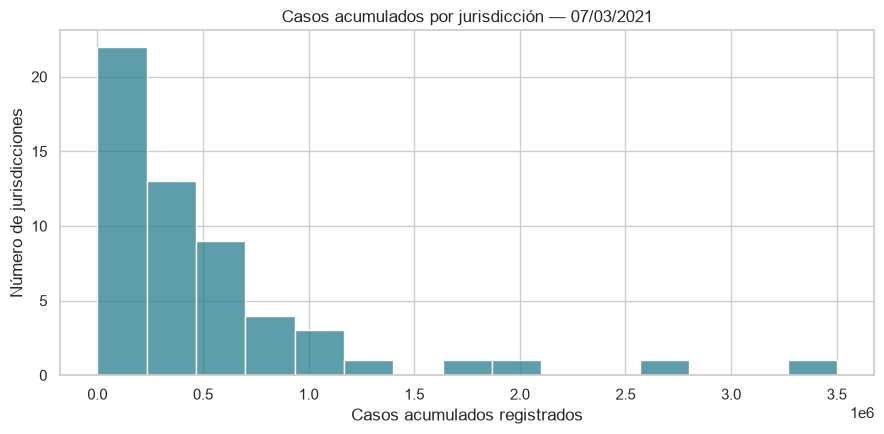

,casos_acumulados
count,"56,00"
mean,"513.508,73"
std,"648.036,40"
min,"0,00"
25%,"101.452,50"
50%,"334.675,00"
75%,"630.258,50"
max,"3.501.394,00"


In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(muestra_final["casos_acumulados"].dropna(), bins=15, color="#287c8e", ax=ax)
ax.set(title=f"Casos acumulados por jurisdicción — {fecha_final:%d/%m/%Y}",
       xlabel="Casos acumulados registrados", ylabel="Número de jurisdicciones")
guardar_figura(fig, "01_histograma_casos.png")
display(muestra_final["casos_acumulados"].describe().to_frame("casos_acumulados"))

**Cómo interpretarlo:** compara la media y la mediana de la salida. Si la media es mayor, unos pocos totales altos pueden estar elevándola. La asimetría es una propiedad de la muestra; no demuestra que algún estado haya medido incorrectamente los datos.

### 7.3. Recuento de registros por estado

Para una variable categórica tiene sentido contar categorías. Cada barra muestra cuántas fechas tiene la jurisdicción. Una cobertura desigual afecta a la interpretación de las comparaciones de periodos completos.


Menor cobertura: 357 | Mayor: 420


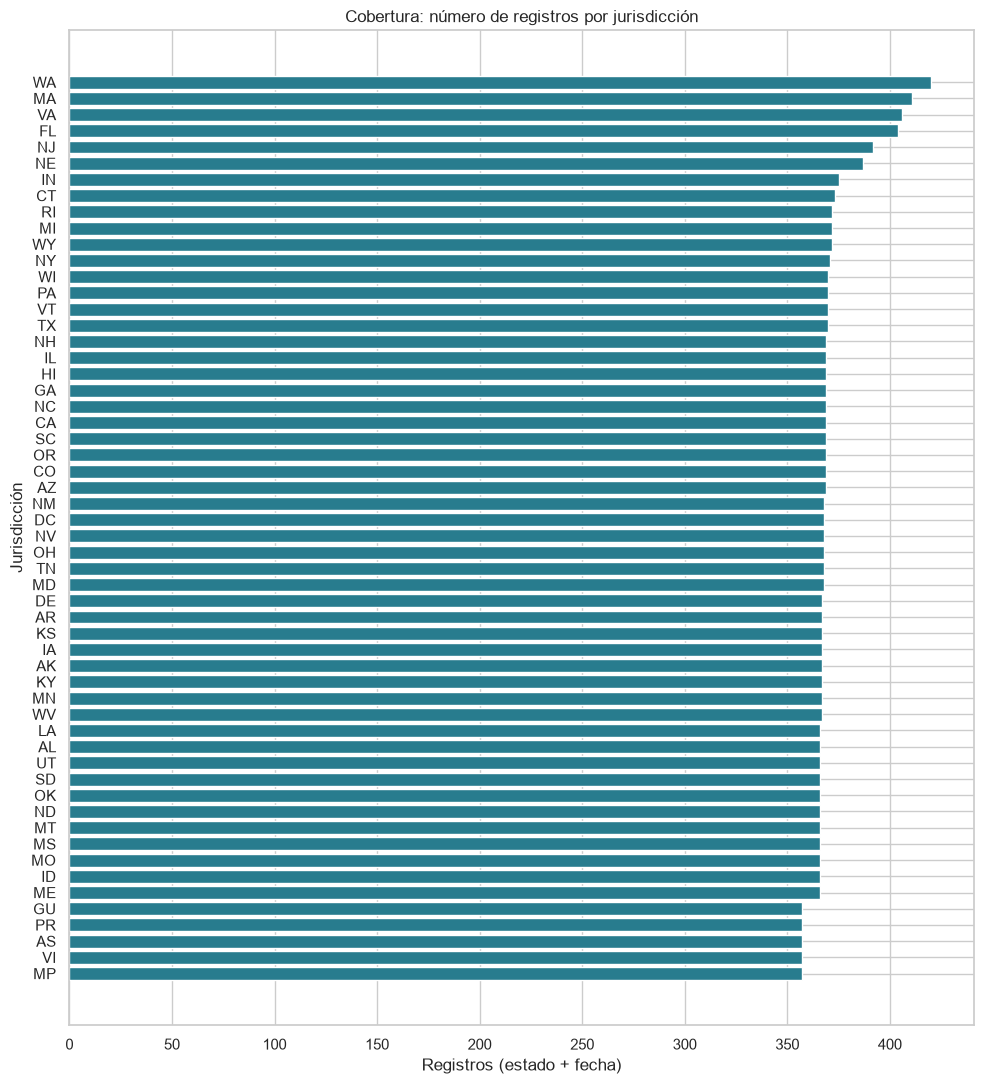

In [17]:
registros_por_estado = df.groupby("estado", observed=True).size().sort_values()
fig, ax = plt.subplots(figsize=(10, 11))
ax.barh(registros_por_estado.index.astype(str), registros_por_estado.values, color="#287c8e")
ax.set(title="Cobertura: número de registros por jurisdicción", xlabel="Registros (estado + fecha)", ylabel="Jurisdicción")
guardar_figura(fig, "02_cobertura_estados.png")
print("Menor cobertura:", int(registros_por_estado.min()), "| Mayor:", int(registros_por_estado.max()))

**Cómo interpretarlo:** las barras más cortas indican menos fechas disponibles. El recuento por sí solo no indica si faltan fechas al principio, en medio o al final. Examinaremos la cobertura por fecha antes de interpretar la evolución del conjunto.

### 7.4. Boxplot de fallecimientos acumulados

El **boxplot** resume una distribución. La línea interior marca la mediana; la caja abarca del primer al tercer cuartil. Los puntos situados más allá de los bigotes son candidatos a valores atípicos según la regla de 1,5 veces el rango intercuartílico.


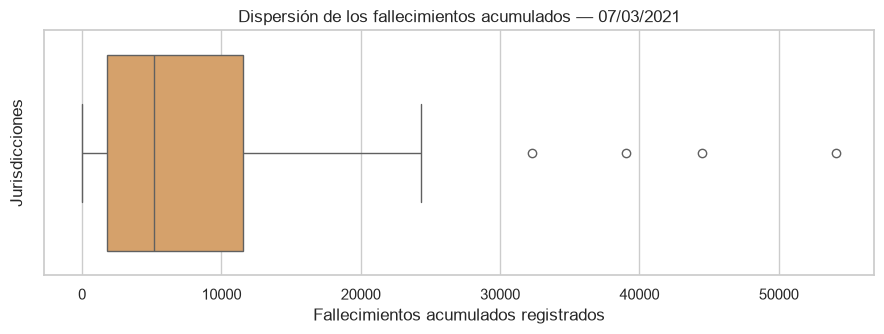

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.boxplot(x=muestra_final["fallecimientos_acumulados"].dropna(), color="#e6a15a", ax=ax)
ax.set(title=f"Dispersión de los fallecimientos acumulados — {fecha_final:%d/%m/%Y}",
       xlabel="Fallecimientos acumulados registrados", ylabel="Jurisdicciones")
guardar_figura(fig, "03_boxplot_fallecimientos.png")

## 8. Investigar valores atípicos mediante la regla del IQR

**Q1** deja el 25% de los valores por debajo; **Q3**, el 75%. **IQR = Q3 − Q1** es la amplitud de la parte central de la distribución. La regla señala los valores inferiores a Q1 − 1,5 × IQR o superiores a Q3 + 1,5 × IQR.

Que un valor esté señalado no significa que sea erróneo. Las jurisdicciones tienen poblaciones, periodos y formas de registro diferentes. **Decisión: conservar los candidatos a valores atípicos**, mostrar cuáles son y no clasificarlos como errores sin investigar su origen.


In [19]:
serie_fallecimientos = muestra_final["fallecimientos_acumulados"].dropna()
q1, q3 = serie_fallecimientos.quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
candidatos_outlier = muestra_final.loc[
    muestra_final["fallecimientos_acumulados"].lt(limite_inferior)
    | muestra_final["fallecimientos_acumulados"].gt(limite_superior),
    ["estado", "fecha", "fallecimientos_acumulados"],
].sort_values("fallecimientos_acumulados", ascending=False)
print(f"Q1={q1:,.1f}; Q3={q3:,.1f}; IQR={iqr:,.1f}")
print(f"Límites: {limite_inferior:,.1f} a {limite_superior:,.1f}")
display(candidatos_outlier)
candidatos_outlier.to_csv(TABLES / "candidatos_atipicos_fallecimientos.csv", index=False)

Q1=1,778.8; Q3=11,512.2; IQR=9,733.5
Límites: -12,821.5 a 26,112.5


,estado,fecha,fallecimientos_acumulados
2194,CA,2021-03-07,"54.124,00"
17751,TX,2021-03-07,"44.451,00"
14076,NY,2021-03-07,"39.029,00"
4075,FL,2021-03-07,"32.266,00"


## 9. Agrupar y resumir

### 9.1. groupby y agg: un resumen por estado

**groupby('estado')** divide la tabla en grupos. **agg** especifica qué resumen queremos de cada columna. La nueva tabla tendrá una fila por estado, no por estado y día.

**size** cuenta registros; **min/max** encuentran la primera/última fecha; **median** calcula la mediana; la suma de un indicador booleano cuenta cuántas correcciones hubo. observed=True conserva únicamente las categorías observadas.


In [20]:
resumen_estados = df.groupby("estado", observed=True).agg(
    registros=("fecha", "size"),
    primera_fecha=("fecha", "min"),
    ultima_fecha=("fecha", "max"),
    mediana_incremento_casos=("casos_incremento", "median"),
    revisiones_casos=("correccion_casos", "sum"),
    hospitalizaciones_informadas=("hospitalizados_actualmente", "count"),
)
resumen_estados["cobertura_hospitalizacion_pct"] = (
    100 * resumen_estados["hospitalizaciones_informadas"] / resumen_estados["registros"]
)
display(resumen_estados.head(10))
resumen_estados.to_csv(TABLES / "resumen_por_estado.csv")

,registros,primera_fecha,ultima_fecha,mediana_incremento_casos,revisiones_casos,hospitalizaciones_informadas,cobertura_hospitalizacion_pct
estado,,,,,,,
AK,367,2020-03-06,2021-03-07,"75,00",0,324,"88,28"
AL,366,2020-03-07,2021-03-07,"1.034,50",0,349,"95,36"
AR,367,2020-03-06,2021-03-07,"662,00",1,351,"95,64"
AS,357,2020-03-16,2021-03-07,"0,00",0,0,"0,00"
AZ,369,2020-03-04,2021-03-07,"1.132,00",0,329,"89,16"
CA,369,2020-03-04,2021-03-07,"4.810,00",0,346,"93,77"
CO,369,2020-03-04,2021-03-07,"521,00",0,352,"95,39"
CT,373,2020-02-29,2021-03-07,"203,00",2,351,"94,10"
DC,368,2020-03-05,2021-03-07,"85,00",0,323,"87,77"


### 9.2. Construir el resumen diario y medir la cobertura

Para la serie del conjunto sumamos **incrementos de distintos estados en el mismo día**. Al sumar hospitalizaciones obtenemos personas hospitalizadas ese día en las jurisdicciones que informaron; ese total puede tener cobertura parcial.

Los recuentos de cobertura son indispensables. Si al principio solo estaban presentes algunos estados, una suma menor puede reflejar ausencia de datos. Para comparar casos y fallecimientos a lo largo del tiempo exigiremos registros de las 56 jurisdicciones e incrementos conocidos.

**asfreq('D')** hace explícitos los días sin registros, si existen, sin inventar valores. La función lambda dentro de agg permite pedir una suma con al menos un valor conocido.


In [21]:
numero_jurisdicciones = int(df["estado"].nunique())
diario = df.groupby("fecha", observed=True).agg(
    casos_netos=("casos_incremento", lambda s: s.sum(min_count=1)),
    fallecimientos_netos=("fallecimientos_incremento", lambda s: s.sum(min_count=1)),
    hospitalizados_reportados=("hospitalizados_actualmente", lambda s: s.sum(min_count=1)),
    jurisdicciones=("estado", "nunique"),
    casos_informados=("casos_incremento", "count"),
    fallecimientos_informados=("fallecimientos_incremento", "count"),
    hospitalizaciones_informadas=("hospitalizados_actualmente", "count"),
).sort_index().asfreq("D")
diario["cobertura_completa"] = (
    diario["jurisdicciones"].eq(numero_jurisdicciones)
    & diario["casos_informados"].eq(numero_jurisdicciones)
    & diario["fallecimientos_informados"].eq(numero_jurisdicciones)
)
diario_completo = diario.loc[diario["cobertura_completa"]].copy()
print("Días en la base:", len(diario), "| Días con cobertura completa:", len(diario_completo))
print("Periodo completo:", diario_completo.index.min().date(), "a", diario_completo.index.max().date())
display(diario.tail())
diario.to_csv(TABLES / "resumen_diario.csv")

Días en la base: 420 | Días con cobertura completa: 357
Periodo completo: 2020-03-16 a 2021-03-07


,casos_netos,fallecimientos_netos,hospitalizados_reportados,jurisdicciones,casos_informados,fallecimientos_informados,hospitalizaciones_informadas,cobertura_completa
fecha,,,,,,,,
2021-03-03,66836,2449,"45.462,00",56,56,56,53,True
2021-03-04,65487,1743,"44.172,00",56,56,56,53,True
2021-03-05,68787,2221,"42.541,00",56,56,56,53,True
2021-03-06,60015,1680,"41.401,00",56,56,56,53,True
2021-03-07,41835,842,"40.199,00",56,56,56,53,True


**Atención al significado:** «cobertura completa» indica la presencia de las jurisdicciones y de los campos elegidos, no la ausencia de infranotificación ni la igualdad de criterios de registro. Las hospitalizaciones tienen su propia cobertura, mostrada por separado.

### 9.3. Totales mensuales sin comparar un mes incompleto con uno entero

Utilizamos únicamente los días con cobertura completa de casos y fallecimientos. Cada mes recibe un recuento de días observados y esperados. Un mes parcial queda identificado y no entra en la elección del mayor **mes completo**.


In [22]:
mensual = diario_completo.groupby(diario_completo.index.to_period("M")).agg(
    casos_netos=("casos_netos", "sum"),
    fallecimientos_netos=("fallecimientos_netos", "sum"),
    dias_observados=("casos_netos", "size"),
)
mensual["dias_del_mes"] = mensual.index.days_in_month
mensual["mes_completo"] = mensual["dias_observados"].eq(mensual["dias_del_mes"])
mensual.index.name = "mes"
display(mensual)
mensual.to_csv(TABLES / "resumen_mensual.csv")

,casos_netos,fallecimientos_netos,dias_observados,dias_del_mes,mes_completo
mes,,,,,
2020-03,191218,4251,16,31,False
2020-04,876279,55315,30,30,True
2020-05,718205,41137,31,31,True
2020-06,831597,19475,30,30,True
2020-07,1900180,25249,31,31,True
2020-08,1457213,30244,31,31,True
2020-09,1192663,23329,30,30,True
2020-10,1892015,23545,31,31,True
2020-11,4475991,37065,30,30,True


### 9.4. pivot_table: cruzar mes y estado

Una **tabla dinámica** tiene grupos en las filas y en las columnas. Aquí: meses en las filas, estados en las columnas y suma de los incrementos netos en las celdas.

No indicamos fill_value=0: una combinación ausente no debe convertirse en un cero inventado. Se guarda la tabla completa; mostramos una parte para facilitar la lectura. Los meses parciales siguen identificados en la tabla mensual anterior.


In [23]:
base_periodo_completo = df.loc[df["fecha"].isin(diario_completo.index)]
pivot_mensual = base_periodo_completo.pivot_table(
    index="mes", columns="estado", values="casos_incremento",
    aggfunc=lambda s: s.sum(min_count=1), observed=True,
)
display(pivot_mensual.iloc[-5:, :10])
pivot_mensual.to_csv(TABLES / "pivot_casos_mes_estado.csv")

estado,AK,AL,AR,AS,AZ,CA,CO,CT,DC,DE
mes,,,,,,,,,,
2020-11,16011,57239,45169,0,80871,290963,125555,46088,4286,10703
2020-12,14138,111702,67779,0,193390,1032411,101192,68413,7431,21802
2021-01,7137,98413,70130,0,238197,997969,62082,64315,7889,20615
2021-02,3391,33613,27147,0,58378,232214,32124,29923,3726,8728
2021-03,897,6567,2403,0,9672,25832,8299,5384,821,1555


## 10. Análisis bivariado — relacionar dos variables

### 10.1. Estado × casos acumulados en la misma fecha

La clasificación responde a la pregunta de **volumen**. nlargest selecciona los diez mayores valores. Después los ordenamos para que la mayor barra horizontal aparezca arriba.

Las etiquetas son siglas oficiales: CA = California; TX = Texas; FL = Florida; NY = Nueva York. No tenemos denominadores poblacionales para elaborar una clasificación del riesgo por habitante.


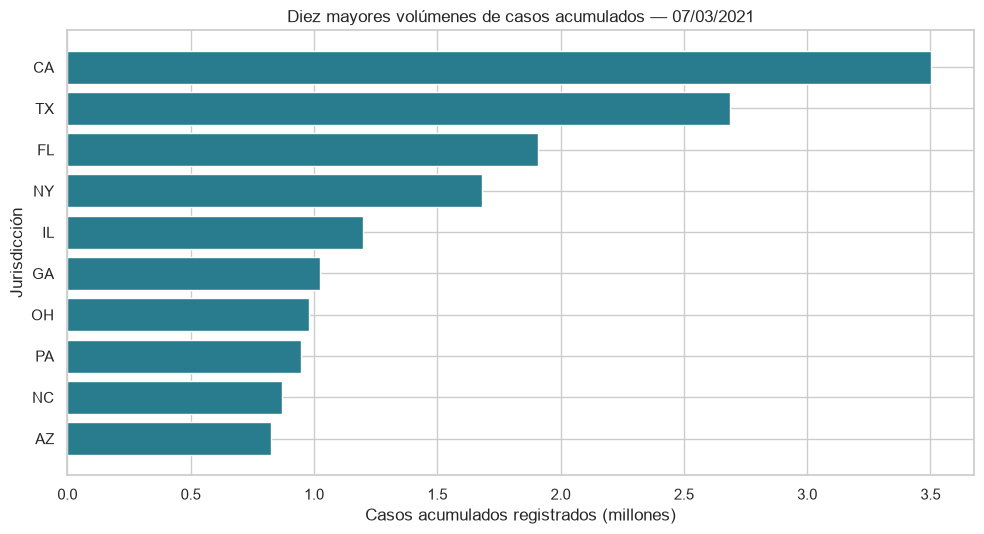

,estado,casos_acumulados,fallecimientos_acumulados
2194,CA,"3.501.394,00","54.124,00"
17751,TX,"2.686.818,00","44.451,00"
4075,FL,"1.909.209,00","32.266,00"
14076,NY,"1.681.169,00","39.029,00"
6272,IL,"1.198.335,00","23.014,00"
4444,GA,"1.023.487,00","17.906,00"
14444,OH,"978.471,00","17.656,00"
15549,PA,"948.643,00","24.349,00"
11455,NC,"872.176,00","11.502,00"
1825,AZ,"826.454,00","16.328,00"


In [24]:
top10 = muestra_final.nlargest(10, "casos_acumulados").sort_values("casos_acumulados")
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top10["estado"].astype(str), top10["casos_acumulados"] / 1_000_000, color="#287c8e")
ax.set(title=f"Diez mayores volúmenes de casos acumulados — {fecha_final:%d/%m/%Y}",
       xlabel="Casos acumulados registrados (millones)", ylabel="Jurisdicción")
guardar_figura(fig, "04_ranking_casos.png")
display(top10[["estado", "casos_acumulados", "fallecimientos_acumulados"]].sort_values("casos_acumulados", ascending=False))

### 10.2. Casos acumulados × fallecimientos acumulados

Cada punto del gráfico de **dispersión** es una jurisdicción en la fecha final. El eje X muestra casos; el Y, fallecimientos. Si los puntos tienden a subir de izquierda a derecha, existe una asociación positiva.

**La asociación no mide causalidad ni la probabilidad individual de morir.** La población, la detección de casos, el periodo de exposición y los criterios de notificación afectan a ambos totales. No utilizamos la división simple fallecimientos/casos como «riesgo individual».


Jurisdicciones con ambas medidas conocidas: 56


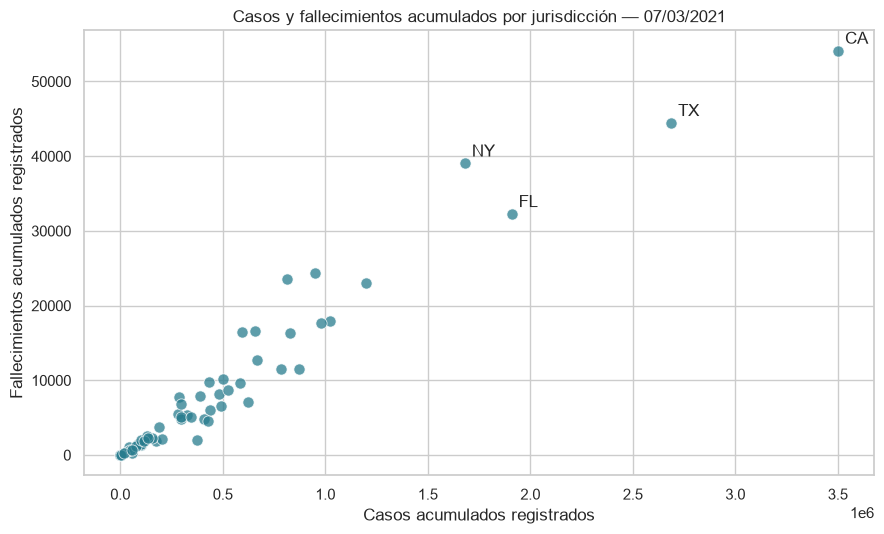

In [25]:
pares = muestra_final.dropna(subset=["casos_acumulados", "fallecimientos_acumulados"])
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=pares, x="casos_acumulados", y="fallecimientos_acumulados",
                s=65, alpha=0.75, color="#287c8e", ax=ax)
for _, fila in pares.nlargest(4, "casos_acumulados").iterrows():
    ax.annotate(str(fila["estado"]), (fila["casos_acumulados"], fila["fallecimientos_acumulados"]),
                xytext=(5, 5), textcoords="offset points")
ax.set(title=f"Casos y fallecimientos acumulados por jurisdicción — {fecha_final:%d/%m/%Y}",
       xlabel="Casos acumulados registrados", ylabel="Fallecimientos acumulados registrados")
guardar_figura(fig, "05_dispersion_casos_fallecimientos.png")
print("Jurisdicciones con ambas medidas conocidas:", len(pares))

## 11. Fecha × registros diarios — la tercera relación

Una línea temporal muestra cómo cambia una variable entre fechas. Mostraremos casos y fallecimientos en **paneles separados**, porque tienen escalas diferentes.

La línea fina representa el incremento neto registrado cada día, incluidas las revisiones. Como apoyo a la lectura, la línea gruesa utiliza la **media móvil de los últimos siete días**: suma siete observaciones y divide entre siete. No utiliza datos futuros ni representa una predicción. Exigimos siete días completos; los huecos se mantienen como nulos.

No interpretaremos la distancia entre picos como el tiempo entre infección y fallecimiento: las fechas de notificación y las revisiones no permiten esa conclusión.


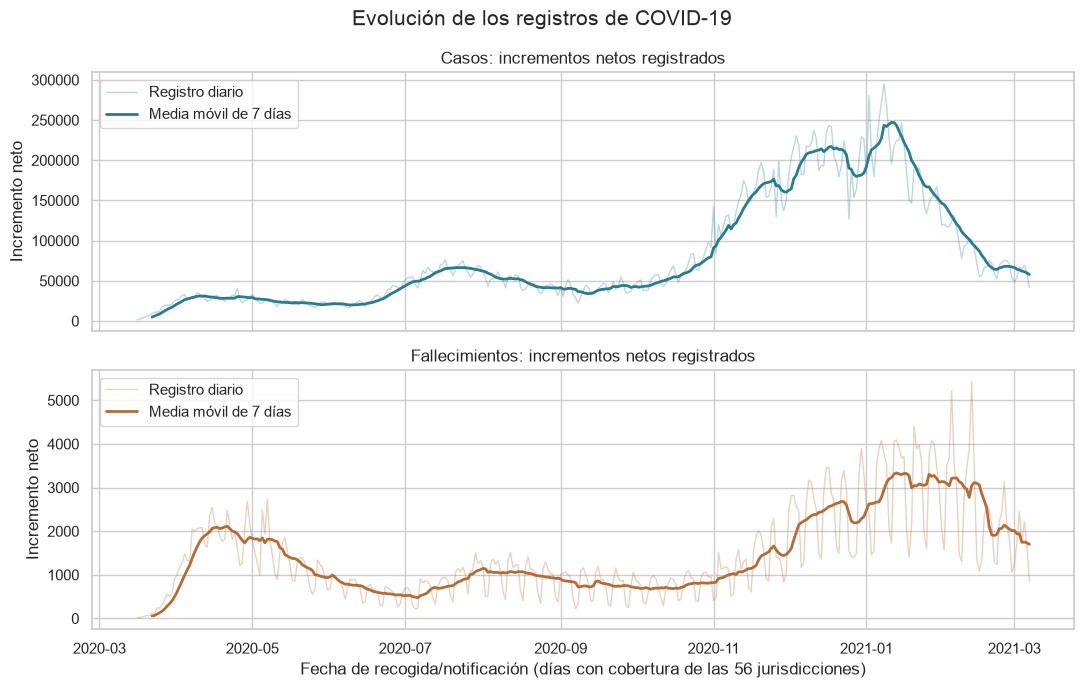

In [26]:
serie_tiempo = diario[["casos_netos", "fallecimientos_netos"]].where(diario["cobertura_completa"])
media_7dias = serie_tiempo.rolling(window=7, min_periods=7).mean()

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, columna, titulo, color in [
    (axes[0], "casos_netos", "Casos: incrementos netos registrados", "#287c8e"),
    (axes[1], "fallecimientos_netos", "Fallecimientos: incrementos netos registrados", "#b56b38"),
]:
    ax.plot(serie_tiempo.index, serie_tiempo[columna], color=color, alpha=0.30, linewidth=1, label="Registro diario")
    ax.plot(media_7dias.index, media_7dias[columna], color=color, linewidth=2, label="Media móvil de 7 días")
    ax.set(title=titulo, ylabel="Incremento neto")
    ax.legend(loc="upper left")
axes[1].set_xlabel("Fecha de recogida/notificación (días con cobertura de las 56 jurisdicciones)")
fig.suptitle("Evolución de los registros de COVID-19", fontsize=15)
guardar_figura(fig, "06_evolucion_temporal.png")

### 11.1. Cuantificar lo que muestra el gráfico

idxmax devuelve la **fecha** del mayor valor; max devuelve el propio valor. Evaluamos los días con cobertura completa. El máximo diario puede estar influido por la acumulación de notificaciones y las correcciones.

Para comparar meses seleccionamos únicamente los completos. Marzo de 2021 termina el día 7, por lo que su suma no representa el mes entero.


In [27]:
fecha_pico_casos = diario_completo["casos_netos"].idxmax()
fecha_pico_fallecimientos = diario_completo["fallecimientos_netos"].idxmax()
meses_completos = mensual.loc[mensual["mes_completo"]]
mes_mayor = meses_completos["casos_netos"].idxmax()
print(f"Mayor incremento de casos: {diario_completo.loc[fecha_pico_casos, 'casos_netos']:,.0f} el {fecha_pico_casos:%d/%m/%Y}")
print(f"Mayor incremento de fallecimientos: {diario_completo.loc[fecha_pico_fallecimientos, 'fallecimientos_netos']:,.0f} el {fecha_pico_fallecimientos:%d/%m/%Y}")
print(f"Mes completo con más incrementos de casos: {mes_mayor} ({mensual.loc[mes_mayor, 'casos_netos']:,.0f})")

Mayor incremento de casos: 295,121 el 08/01/2021
Mayor incremento de fallecimientos: 5,427 el 12/02/2021
Mes completo con más incrementos de casos: 2020-12 (6,323,266)


### 11.2. Cobertura de las hospitalizaciones

Un total hospitalario puede variar porque cambió el número de pacientes, porque más estados empezaron a informar o por ambos motivos. Mostrar únicamente la suma ocultaría este problema.

El siguiente gráfico distingue entre **presencia de una fila** y **presencia del indicador hospitalario**. La línea de referencia muestra el total de jurisdicciones. Este control respalda la decisión de conservar los nulos.


Sin hospitalización informada en la fecha final: ['AS', 'MP', 'VI']


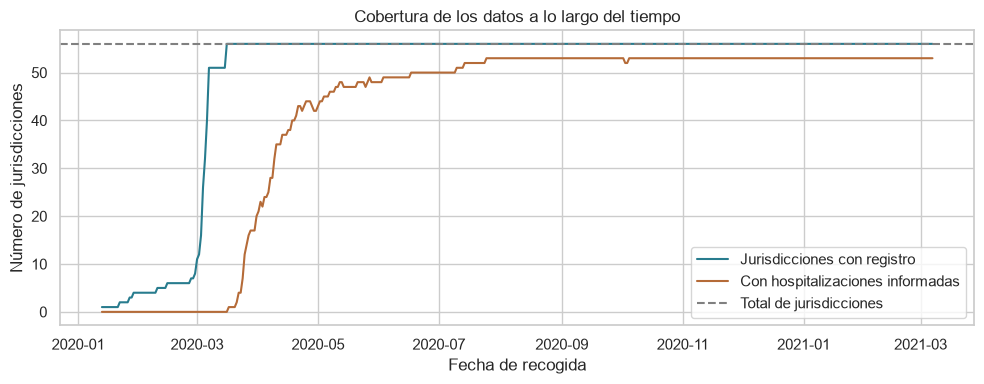

In [28]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(diario.index, diario["jurisdicciones"], label="Jurisdicciones con registro", color="#287c8e")
ax.plot(diario.index, diario["hospitalizaciones_informadas"], label="Con hospitalizaciones informadas", color="#b56b38")
ax.axhline(numero_jurisdicciones, color="gray", linestyle="--", label="Total de jurisdicciones")
ax.set(title="Cobertura de los datos a lo largo del tiempo", xlabel="Fecha de recogida", ylabel="Número de jurisdicciones")
ax.legend()
guardar_figura(fig, "07_cobertura_temporal.png")
print("Sin hospitalización informada en la fecha final:", muestra_final.loc[
    muestra_final["hospitalizados_actualmente"].isna(), "estado"
].astype(str).tolist())

### 11.3. Leer la tabla dinámica como un mapa de calor

Un **mapa de calor** transforma los valores en intensidades de color. Aquí comparamos los cinco mayores volúmenes finales, utilizando únicamente meses completos. Las celdas representan incrementos netos mensuales, no totales acumulados.

Los colores más intensos indican mayor volumen registrado. Esto no normaliza por población ni corrige las diferencias de duración entre meses.


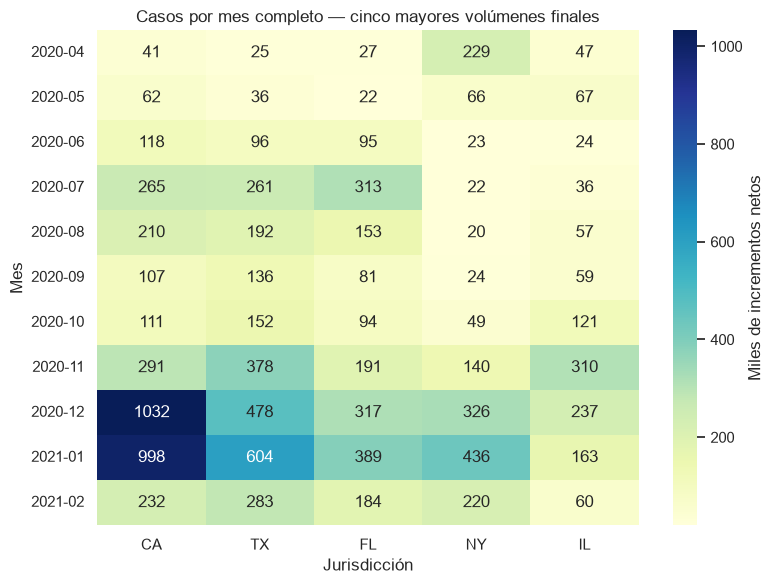

In [29]:
estados_top5 = muestra_final.nlargest(5, "casos_acumulados")["estado"].astype(str).tolist()
meses_validos = meses_completos.index.astype(str)
mapa_calor_mensual = pivot_mensual.loc[meses_validos, estados_top5] / 1000
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(mapa_calor_mensual, annot=True, fmt=".0f", cmap="YlGnBu",
            cbar_kws={"label": "Miles de incrementos netos"}, ax=ax)
ax.set(title="Casos por mes completo — cinco mayores volúmenes finales",
       xlabel="Jurisdicción", ylabel="Mes")
guardar_figura(fig, "08_mapa_calor_mensual.png")

## 12. Matriz de correlación e interpretación

La **correlación de Pearson** resume una asociación lineal y varía entre −1 y +1. Los valores próximos a +1 indican que ambas medidas tienden a aumentar juntas; próximos a −1, a variar en sentidos opuestos. Cerca de cero significa poca asociación **lineal**, no ausencia de cualquier relación.

Utilizamos una fila por jurisdicción en la misma fecha, evitando mezclar cientos de observaciones repetidas de cada estado. La diagonal vale 1 para las variables que tienen variación.

Pandas utiliza pares con valores conocidos. Como las hospitalizaciones tienen nulos, el tamaño de la muestra puede variar entre pares. La segunda tabla lo hace explícito. La población y otros factores no controlados limitan la interpretación.


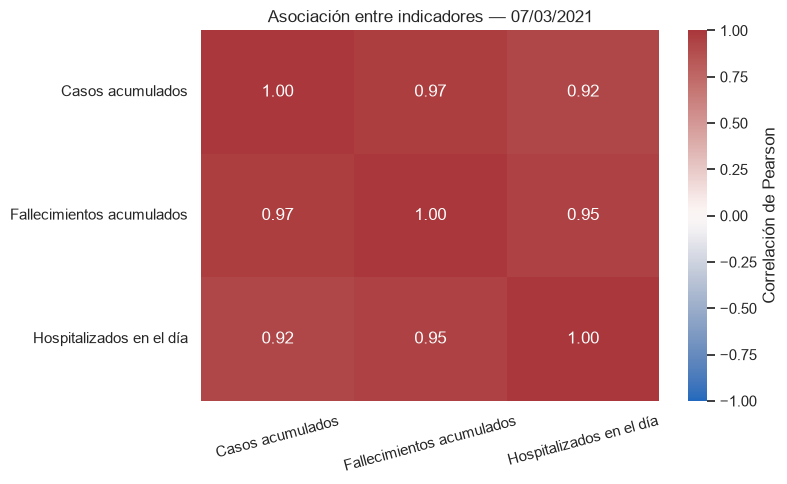

,Casos acumulados,Fallecimientos acumulados,Hospitalizados en el día
Casos acumulados,56,56,53
Fallecimientos acumulados,56,56,53
Hospitalizados en el día,53,53,53


In [30]:
variables_correlacion = ["casos_acumulados", "fallecimientos_acumulados", "hospitalizados_actualmente"]
matriz_correlacion = muestra_final[variables_correlacion].corr(method="pearson", min_periods=3)
presencia = muestra_final[variables_correlacion].notna().astype(int)
cantidad_pares = presencia.T @ presencia

etiquetas = ["Casos acumulados", "Fallecimientos acumulados", "Hospitalizados en el día"]
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(matriz_correlacion, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0,
            cmap="vlag", xticklabels=etiquetas, yticklabels=etiquetas,
            cbar_kws={"label": "Correlación de Pearson"}, ax=ax)
ax.set_title(f"Asociación entre indicadores — {fecha_final:%d/%m/%Y}")
ax.tick_params(axis="x", rotation=15)
guardar_figura(fig, "09_correlacion.png")
display(cantidad_pares.rename(index=dict(zip(variables_correlacion, etiquetas)), columns=dict(zip(variables_correlacion, etiquetas))))
matriz_correlacion.to_csv(TABLES / "correlaciones.csv")
cantidad_pares.to_csv(TABLES / "muestras_correlaciones.csv")

In [31]:
r_casos_fallecimientos = float(matriz_correlacion.loc["casos_acumulados", "fallecimientos_acumulados"])
display(Markdown(
    f"**Lectura del resultado:** los casos y los fallecimientos acumulados presentan una correlación "
    f"de Pearson **r = {numero(r_casos_fallecimientos, 3)}**, con **{len(pares)} jurisdicciones**. "
    "Existe una asociación lineal positiva fuerte en esta muestra. El resultado no identifica "
    "causas, no controla el tamaño de la población y no representa una tasa de letalidad. "
    "Las correlaciones que incluyen hospitalizaciones tienen menos pares y combinan "
    "una medida del día con totales acumulados; son descripciones, no estimaciones de riesgo."
))


**Lectura del resultado:** los casos y los fallecimientos acumulados presentan una correlación de Pearson **r = 0,967**, con **56 jurisdicciones**. Existe una asociación lineal positiva fuerte en esta muestra. El resultado no identifica causas, no controla el tamaño de la población y no representa una tasa de letalidad. Las correlaciones que incluyen hospitalizaciones tienen menos pares y combinan una medida del día con totales acumulados; son descripciones, no estimaciones de riesgo.

## 13. Responder a las preguntas con evidencias calculadas

Volvemos a las preguntas formuladas al principio. Las cifras del siguiente texto se generan a partir de las tablas analizadas, para no depender de valores copiados manualmente.

Observa la diferencia entre un **resultado** («CA tiene el mayor volumen») y una **interpretación que requeriría más datos** («CA tiene el mayor riesgo»). Solo la primera afirmación está respaldada por esta comparación.


In [32]:
total_casos = float(muestra_final["casos_acumulados"].sum(min_count=1))
total_fallecimientos = float(muestra_final["fallecimientos_acumulados"].sum(min_count=1))
top3 = muestra_final.nlargest(3, "casos_acumulados")
participacion_top3 = float(100 * top3["casos_acumulados"].sum() / total_casos)
ranking_texto = "; ".join(f"{fila.estado}: {numero(fila.casos_acumulados)}" for fila in top3.itertuples())

conclusiones = f"""
### 1. ¿Cómo evolucionaron los registros?
La serie presenta oscilaciones y concentra volúmenes altos a finales de 2020 y principios de 2021.
El mayor incremento diario de casos registrado fue **{numero(diario_completo.loc[fecha_pico_casos, 'casos_netos'])} el {fecha_pico_casos:%d/%m/%Y}**;
el de fallecimientos fue **{numero(diario_completo.loc[fecha_pico_fallecimientos, 'fallecimientos_netos'])} el {fecha_pico_fallecimientos:%d/%m/%Y}**.
El mes completo con más incrementos de casos fue **{mes_mayor}**, con **{numero(mensual.loc[mes_mayor, 'casos_netos'])}**.
Son fechas de registro, no necesariamente de los hechos; no inferimos un desfase biológico entre esos picos.

### 2. ¿Qué jurisdicciones concentraron más casos en la misma fecha?
El **{fecha_final:%d/%m/%Y}**, los tres mayores volúmenes fueron **{ranking_texto}**.
Juntos representan el **{numero(participacion_top3, 1)}%** del acumulado conocido de **{numero(total_casos)} casos**.
El acumulado de fallecimientos en la misma fecha es **{numero(total_fallecimientos)}**.
Estos volúmenes no están ajustados por población y no definen una clasificación del riesgo individual.

### 3. ¿Existe asociación entre casos y fallecimientos acumulados?
Sí: **r = {numero(r_casos_fallecimientos, 3)}**, para **{len(pares)} jurisdicciones** en la fecha final.
La asociación lineal es positiva y fuerte en esta muestra. La población, la detección y los criterios de notificación
pueden influir en ambos totales. La correlación no establece causalidad.

### 4. ¿Qué problemas limitan la interpretación?
No se identificaron duplicados exactos (**{duplicados_exactos}**).
En la base completa faltan **{numero(df['hospitalizados_actualmente'].isna().sum())}** valores de hospitalización.
Se conservaron **{int(correcciones['casos_incremento'])}** incrementos negativos de casos y
**{int(correcciones['fallecimientos_incremento'])}** de fallecimientos.
La serie temporal comparable de casos y fallecimientos utiliza **{len(diario_completo)} días** con registros de las
**{numero_jurisdicciones} jurisdicciones**. Marzo de 2021 es parcial y no entra en la clasificación de meses completos.
"""
display(Markdown(conclusiones))
(ROOT / "reports/conclusiones.md").write_text(conclusiones.strip() + "\n", encoding="utf-8")


Out[32]: 1643



### 1. ¿Cómo evolucionaron los registros?
La serie presenta oscilaciones y concentra volúmenes altos a finales de 2020 y principios de 2021.
El mayor incremento diario de casos registrado fue **295.121 el 08/01/2021**;
el de fallecimientos fue **5.427 el 12/02/2021**.
El mes completo con más incrementos de casos fue **2020-12**, con **6.323.266**.
Son fechas de registro, no necesariamente de los hechos; no inferimos un desfase biológico entre esos picos.

### 2. ¿Qué jurisdicciones concentraron más casos en la misma fecha?
El **07/03/2021**, los tres mayores volúmenes fueron **CA: 3.501.394; TX: 2.686.818; FL: 1.909.209**.
Juntos representan el **28,2%** del acumulado conocido de **28.756.489 casos**.
El acumulado de fallecimientos en la misma fecha es **515.151**.
Estos volúmenes no están ajustados por población y no definen una clasificación del riesgo individual.

### 3. ¿Existe asociación entre casos y fallecimientos acumulados?
Sí: **r = 0,967**, para **56 jurisdicciones** en la fecha final.
La asociación lineal es positiva y fuerte en esta muestra. La población, la detección y los criterios de notificación
pueden influir en ambos totales. La correlación no establece causalidad.

### 4. ¿Qué problemas limitan la interpretación?
No se identificaron duplicados exactos (**0**).
En la base completa faltan **3.441** valores de hospitalización.
Se conservaron **24** incrementos negativos de casos y
**73** de fallecimientos.
La serie temporal comparable de casos y fallecimientos utiliza **357 días** con registros de las
**56 jurisdicciones**. Marzo de 2021 es parcial y no entra en la clasificación de meses completos.


### 13.1. Qué recomendamos al cliente

- Para evaluar el **volumen operativo**, considerar la concentración de registros y seguir la serie diaria con cobertura explícita.
- Para comparar el **riesgo entre poblaciones**, añadir denominadores poblacionales en una etapa futura y mantener fechas y definiciones comparables.
- Para vigilar las hospitalizaciones, presentar la disponibilidad del indicador junto con sus valores; no convertir la ausencia en cero.
- Antes de tomar decisiones sobre la situación actual, buscar una fuente actualizada: este archivo termina en marzo de 2021.

Estas recomendaciones se refieren a la interpretación y a la calidad de los datos. El ejercicio es descriptivo y no evalúa causalidad, políticas públicas ni tratamientos.


## 14. Generar el informe ejecutivo de dos páginas

El CEO no necesita leer cada celda. El informe debe responder: **qué encontramos, por qué importa y cuáles son las limitaciones**.

Guardaremos los principales resultados en JSON, un archivo estructurado de claves y valores. El script generar_informe.py utiliza ese resumen y las figuras ya producidas para construir dos páginas en PDF. No repite ni modifica la limpieza; solo organiza la presentación.


In [33]:
import json

resumen = {
    "filas_brutas": int(filas), "columnas_brutas": int(columnas),
    "jurisdicciones": numero_jurisdicciones,
    "fecha_inicial": df["fecha"].min().strftime("%Y-%m-%d"),
    "fecha_final": fecha_final.strftime("%Y-%m-%d"),
    "inicio_cobertura_completa": diario_completo.index.min().strftime("%Y-%m-%d"),
    "dias_cobertura_completa": len(diario_completo),
    "total_casos": total_casos, "total_fallecimientos": total_fallecimientos,
    "fecha_pico_casos": fecha_pico_casos.strftime("%Y-%m-%d"),
    "pico_casos_valor": int(diario_completo.loc[fecha_pico_casos, "casos_netos"]),
    "fecha_pico_fallecimientos": fecha_pico_fallecimientos.strftime("%Y-%m-%d"),
    "pico_fallecimientos_valor": int(diario_completo.loc[fecha_pico_fallecimientos, "fallecimientos_netos"]),
    "mes_mayor_casos": str(mes_mayor),
    "mes_mayor_casos_valor": int(mensual.loc[mes_mayor, "casos_netos"]),
    "top3": [{"estado": str(r.estado), "casos": int(r.casos_acumulados)} for r in top3.itertuples()],
    "top3_participacion_pct": participacion_top3,
    "correlacion_casos_fallecimientos": r_casos_fallecimientos,
    "pares_casos_fallecimientos": len(pares),
    "duplicados_exactos": duplicados_exactos,
    "columnas_mas_80_pct_nulos": int(calidad_original["porcentaje_nulos"].gt(80).sum()),
    "nulos_hospitalizacion": int(df["hospitalizados_actualmente"].isna().sum()),
    "sin_hospitalizacion_final": muestra_final.loc[muestra_final["hospitalizados_actualmente"].isna(), "estado"].astype(str).tolist(),
    "correcciones_casos": int(correcciones["casos_incremento"]),
    "correcciones_fallecimientos": int(correcciones["fallecimientos_incremento"]),
    "correcciones_pruebas": int(correcciones["pruebas_incremento_referencia"]),
    "valores_atipicos_fallecimientos": candidatos_outlier["estado"].astype(str).tolist(),
}
(ROOT / "reports/resumen_resultados.json").write_text(
    json.dumps(resumen, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)
from generar_informe import generar_informe
ruta_informe = generar_informe(ROOT)
print("Informe generado:", ruta_informe)

Informe generado: /Volumes/SSD-FABI/workspace/factoria/IA SCHOOL/ai_project_EDA/reports/informe_ejecutivo.pdf


## 15. Comprobar la entrega y consolidar el aprendizaje

| Requisito | Evidencia en este notebook |
|---|---|
| Inspección inicial completa | Sección 4 |
| Duplicados, tipos y nulos | Sección 5 |
| Selección y renombrado justificados | Secciones 5.3 y 5.5; CSV de decisiones |
| Tres variables univariadas | Sección 7: casos, estado y fallecimientos |
| Valores atípicos con decisión | Sección 8 |
| groupby, agg y pivot_table | Sección 9 |
| Tres o más variables nuevas | Sección 6: cinco variables |
| Tres relaciones bivariadas | Secciones 10 y 11 |
| Al menos cinco visualizaciones | Nueve archivos en reports/figures |
| Tendencias y correlación interpretadas | Secciones 11 y 12 |
| Tres preguntas respondidas | Sección 13: cuatro respuestas |
| Informe de 1 a 2 páginas | reports/informe_ejecutivo.pdf |
| Instalación y reproducibilidad | README.md y requirements.txt |

**Comprobación final:** reinicia el kernel y ejecuta todas las celdas. Comprueba que el PDF tiene dos páginas y que puedes explicar cada decisión sin limitarte a leer el código. Completa el control de versiones en tu repositorio Git antes de entregar.

**Preguntas para practicar:** ¿por qué no sumamos acumulados de días diferentes? ¿Por qué un nulo no se convierte en cero? ¿Un valor atípico siempre es un error? ¿Qué cambia si un mes solo tiene siete días? ¿Qué no permite concluir una correlación fuerte?

### Referencias y transparencia

- [Enunciado de Factoria F5](https://github.com/Factoria-F5-madrid/ai_project_EDA).
- [Datos oficiales del COVID Tracking Project](https://covidtracking.com/data/download/) y [definiciones de las variables](https://covidtracking.com/about-data/data-definitions/).
- [Notebook de Elena Almansa Campos](https://github.com/elenaalmansacampos/ai_project_EDA/blob/main/notebooks/eda_covid19.ipynb), consultado como referencia de organización. Las decisiones, los cálculos y los textos de esta versión se desarrollaron para el nivel medio y se comprobaron con el CSV oficial.

La versión de referencia rellena algunos acumulados con el último valor conocido. Aquí conservamos los nulos para no presuponer estabilidad durante la ausencia. También utilizamos una fecha final común y explicitamos la cobertura y los meses incompletos. Son decisiones metodológicas propias, documentadas para poder debatirlas.
